In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("COVID-19 world dataset.csv")

print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Total rows and columns: (92375, 7)


,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
0,15-02-20,Afghanistan,0,NaN,0.0,0.0,NaN
1,25-02-20,Afghanistan,1,0.0,1.0,0.0,0.0
2,22-03-20,Afghanistan,40,16.0,38.0,1.0,1.0
3,23-03-20,Afghanistan,40,0.0,38.0,1.0,0.0
4,25-03-20,Afghanistan,84,10.0,80.0,2.0,1.0
5,26-03-20,Afghanistan,94,10.0,88.0,4.0,2.0
6,27-03-20,Afghanistan,110,16.0,104.0,4.0,0.0
7,02-04-20,Afghanistan,273,36.0,257.0,6.0,2.0
8,03-04-20,Afghanistan,281,8.0,265.0,6.0,0.0
9,04-04-20,Afghanistan,309,28.0,292.0,7.0,1.0


In [5]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Column Names:
['date', 'country', 'cumulative_total_cases', 'daily_new_cases', 'active_cases', 'cumulative_total_deaths', 'daily_new_deaths']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 92375 entries, 0 to 92374
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     92375 non-null  str    
 1   country                  92375 non-null  str    
 2   cumulative_total_cases   92375 non-null  int64  
 3   daily_new_cases          92370 non-null  float64
 4   active_cases             83586 non-null  float64
 5   cumulative_total_deaths  92374 non-null  float64
 6   daily_new_deaths         92328 non-null  float64
dtypes: float64(4), int64(1), str(2)
memory usage: 4.9 MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,92375,844,30-09-21,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,92375,215,Iran,814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cumulative_total_cases,92375.0,NaN,NaN,NaN,1414984.094419,5109171.841854,0.0,32788.5,184334.0,753094.5,84209473.0
daily_new_cases,92370.0,NaN,NaN,NaN,5595.851608,24154.958999,-322.0,132.0,605.0,2498.0,909610.0
active_cases,83586.0,NaN,NaN,NaN,121667.30943,551916.439618,-14321.0,2858.25,12368.5,50793.75,17935434.0
cumulative_total_deaths,92374.0,NaN,NaN,NaN,26273.371901,82024.700706,0.0,562.0,3050.0,14721.0,1026646.0
daily_new_deaths,92328.0,NaN,NaN,NaN,68.072448,232.707465,-39.0,2.0,8.0,35.0,5093.0


In [6]:
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing Values,Missing Percentage
date,0,0.00
country,0,0.00
cumulative_total_cases,0,0.00
daily_new_cases,5,0.01
active_cases,8789,9.51
cumulative_total_deaths,1,0.00
daily_new_deaths,47,0.05


In [7]:
print("Total duplicate rows:", df.duplicated().sum())


display(df[df.duplicated(keep=False)].head(20))

Total duplicate rows: 0


,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths


In [8]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (92375, 7)
Remaining duplicate rows: 0


In [9]:
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%y",
    errors="coerce"
)

df["country"] = df["country"].astype("string").str.strip()

numeric_columns = [
    "cumulative_total_cases",
    "daily_new_cases",
    "active_cases",
    "cumulative_total_deaths",
    "daily_new_deaths"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data types after cleaning:")
print(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Data types after cleaning:
date                       datetime64[us]
country                            string
cumulative_total_cases              int64
daily_new_cases                   float64
active_cases                      float64
cumulative_total_deaths           float64
daily_new_deaths                  float64
dtype: object

Date range:
2020-01-22 00:00:00 to 2022-05-14 00:00:00


In [10]:
print("Rows:", len(df))
print("Countries:", df["country"].nunique())
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values after conversion:")
display(df.isnull().sum())

print("\nFirst 5 cleaned rows:")
display(df.head())

Rows: 92375
Countries: 215
Duplicate rows: 0

Missing values after conversion:


date                          0
country                       0
cumulative_total_cases        0
daily_new_cases               5
active_cases               8789
cumulative_total_deaths       1
daily_new_deaths             47
dtype: int64


First 5 cleaned rows:


,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
0,2020-02-15,Afghanistan,0,NaN,0.0,0.0,NaN
1,2020-02-25,Afghanistan,1,0.0,1.0,0.0,0.0
2,2020-03-22,Afghanistan,40,16.0,38.0,1.0,1.0
3,2020-03-23,Afghanistan,40,0.0,38.0,1.0,0.0
4,2020-03-25,Afghanistan,84,10.0,80.0,2.0,1.0


In [11]:
df = df.sort_values(
    ["country", "date"]
).reset_index(drop=True)

df.to_csv("COVID19_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)

print("EDA setup completed!")
print("Dataset shape:", df.shape)

EDA setup completed!
Dataset shape: (92375, 7)


In [13]:
print("========== COVID-19 PROJECT KPIs ==========")

print("Total Records:", len(df))
print("Countries Covered:", df["country"].nunique())

print(
    "Date Range:",
    df["date"].min(),
    "to",
    df["date"].max()
)

print(
    "Highest Reported Cumulative Cases:",
    f"{df['cumulative_total_cases'].max():,.0f}"
)

print(
    "Highest Reported Cumulative Deaths:",
    f"{df['cumulative_total_deaths'].max():,.0f}"
)

print("============================================")

========== COVID-19 PROJECT KPIs ==========
Total Records: 92375
Countries Covered: 215
Date Range: 2020-01-22 00:00:00 to 2022-05-14 00:00:00
Highest Reported Cumulative Cases: 84,209,473
Highest Reported Cumulative Deaths: 1,026,646


,country,cumulative_total_cases
0,USA,84209473
1,India,43121599
2,Brazil,30682094
3,France,29160802
4,Germany,25774509
5,UK,22159805
6,Russia,18255337
7,South Korea,17756627
8,Italy,17030711
9,Turkey,15053168


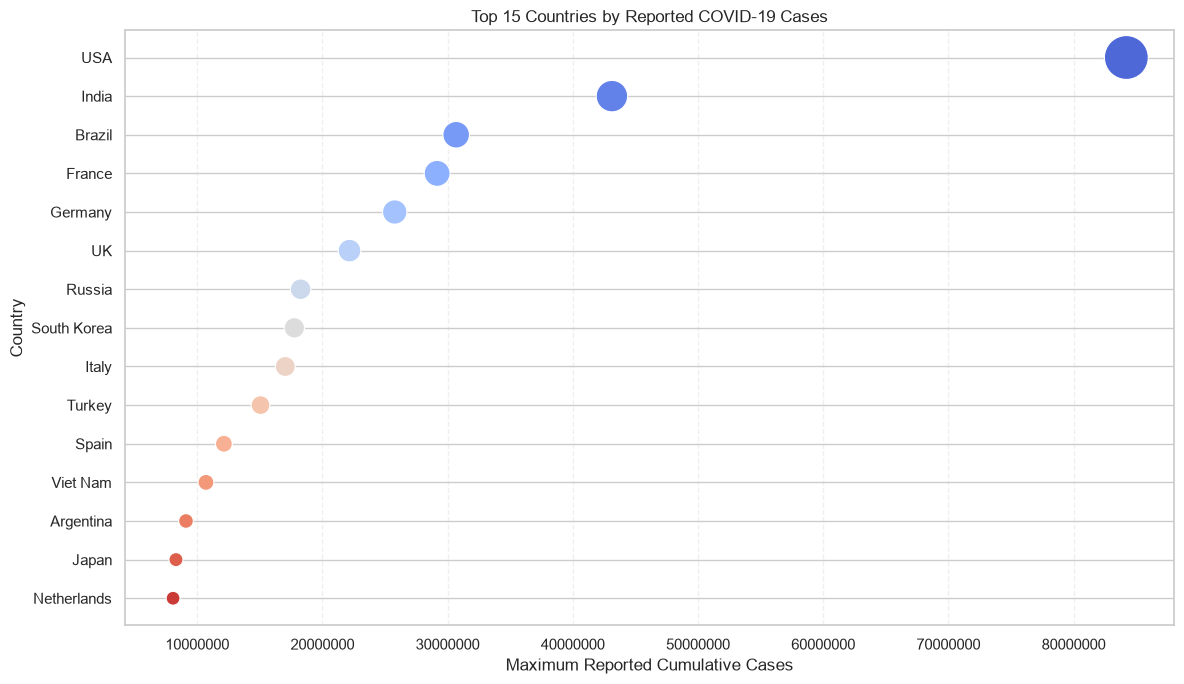

In [14]:
top_cases = (
    df.groupby("country")["cumulative_total_cases"]
      .max()
      .sort_values(ascending=False)
      .head(15)
      .reset_index()
)

display(top_cases)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top_cases,
    x="cumulative_total_cases",
    y="country",
    hue="country",
    size="cumulative_total_cases",
    sizes=(100, 1000),
    palette="coolwarm",
    legend=False
)

plt.title("Top 15 Countries by Reported COVID-19 Cases")
plt.xlabel("Maximum Reported Cumulative Cases")
plt.ylabel("Country")
plt.ticklabel_format(style="plain", axis="x")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

,country,cumulative_total_deaths
0,USA,1026646.0
1,Brazil,664920.0
2,India,524214.0
3,Russia,377571.0
4,Mexico,324465.0
5,Peru,213023.0
6,UK,176708.0
7,Italy,165182.0
8,Indonesia,156453.0
9,France,147257.0


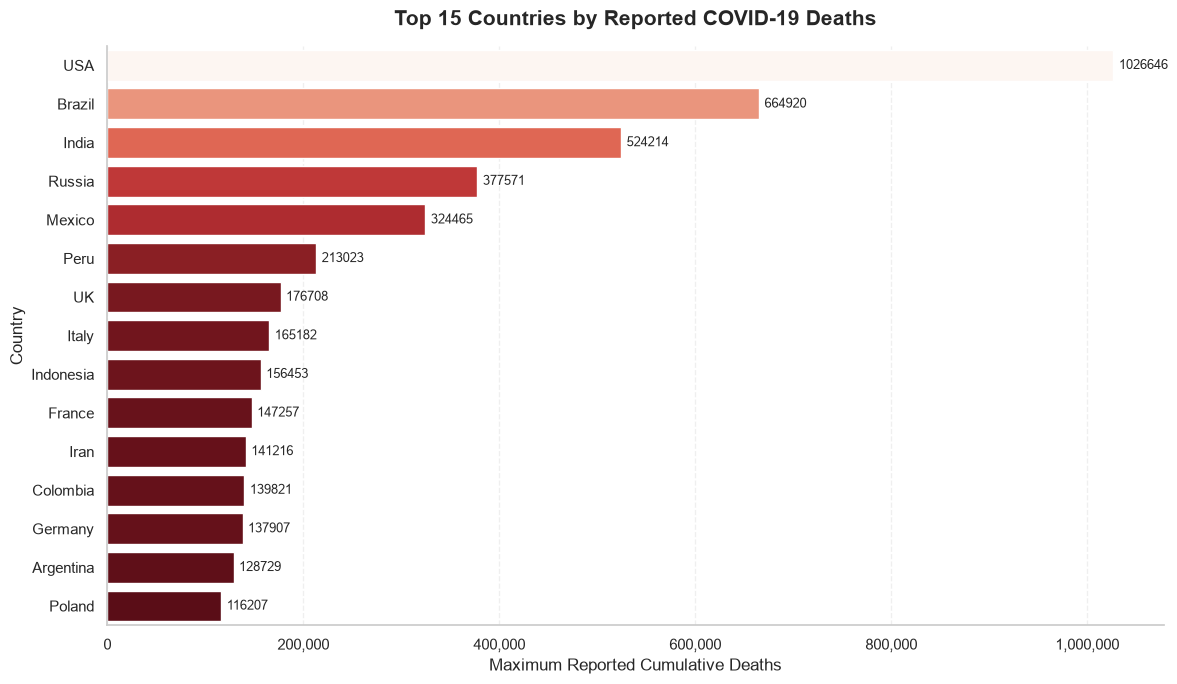

In [15]:
top_deaths = (
    df.groupby("country")["cumulative_total_deaths"]
      .max()
      .sort_values(ascending=False)
      .head(15)
      .reset_index()
)

display(top_deaths)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_deaths,
    x="cumulative_total_deaths",
    y="country",
    hue="cumulative_total_deaths",
    palette="Reds_r",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=9)

plt.title("Top 15 Countries by Reported COVID-19 Deaths",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Maximum Reported Cumulative Deaths")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)
sns.despine()
plt.tight_layout()
plt.show()

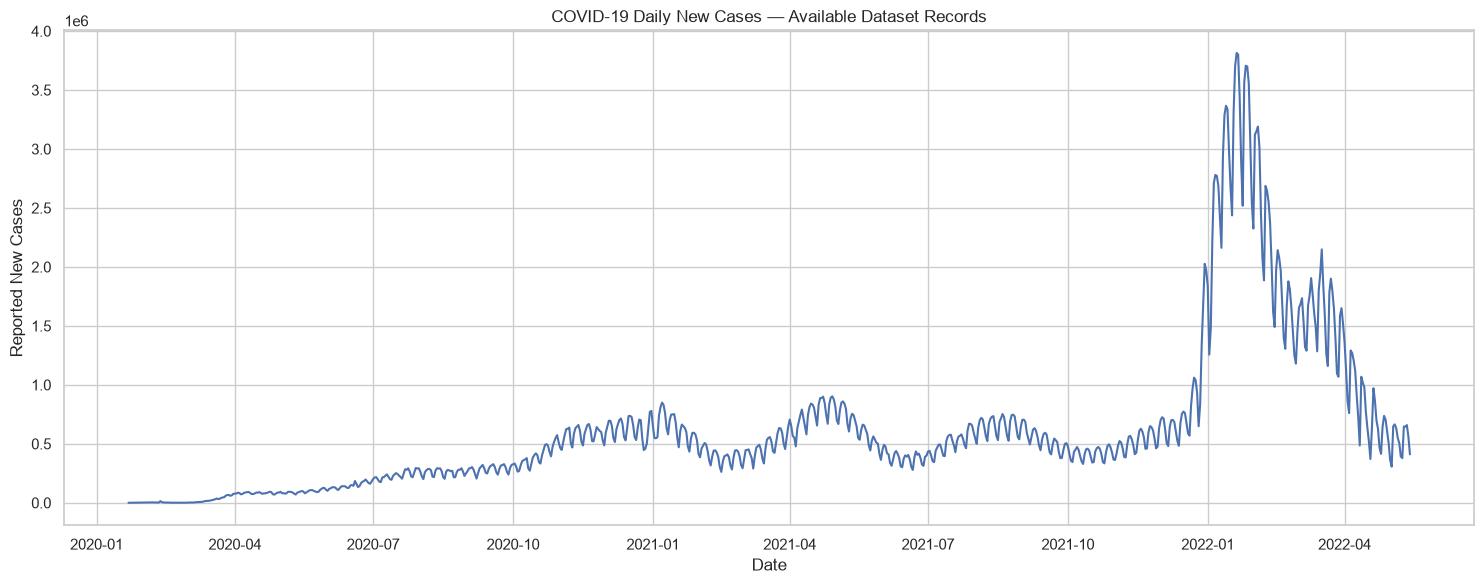

In [16]:
daily_trend = (
    df.groupby("date", as_index=False)
      .agg(
          daily_cases=("daily_new_cases", "sum"),
          daily_deaths=("daily_new_deaths", "sum")
      )
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_trend,
    x="date",
    y="daily_cases"
)

plt.title("COVID-19 Daily New Cases — Available Dataset Records")
plt.xlabel("Date")
plt.ylabel("Reported New Cases")
plt.tight_layout()
plt.show()

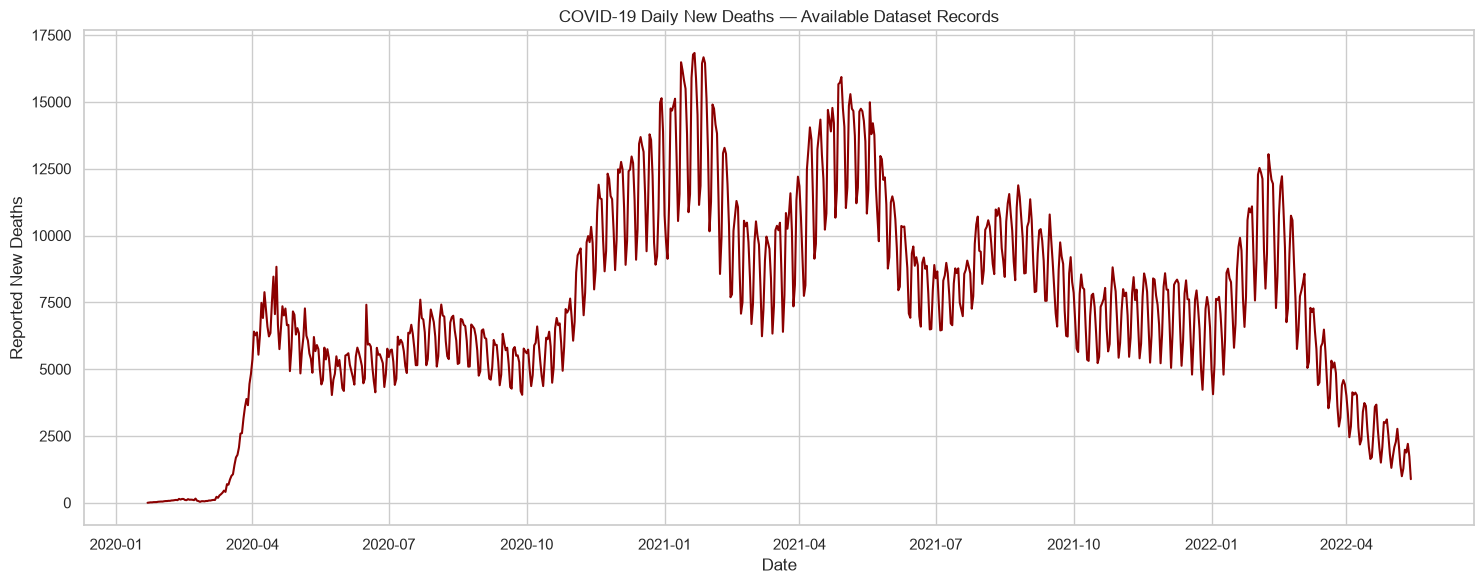

In [17]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=daily_trend,
    x="date",
    y="daily_deaths",
    color="darkred"
)

plt.title("COVID-19 Daily New Deaths — Available Dataset Records")
plt.xlabel("Date")
plt.ylabel("Reported New Deaths")
plt.tight_layout()
plt.show()

,date,daily_cases,daily_deaths
0,2020-01-01,11220.0,242.0
1,2020-02-01,70620.0,2691.0
2,2020-03-01,832619.0,42878.0
3,2020-04-01,2462991.0,201801.0
4,2020-05-01,2943093.0,168267.0
5,2020-06-01,4372334.0,157900.0
6,2020-07-01,7262997.0,185311.0
7,2020-08-01,7997681.0,190267.0
8,2020-09-01,8565101.0,162389.0
9,2020-10-01,12229970.0,183420.0


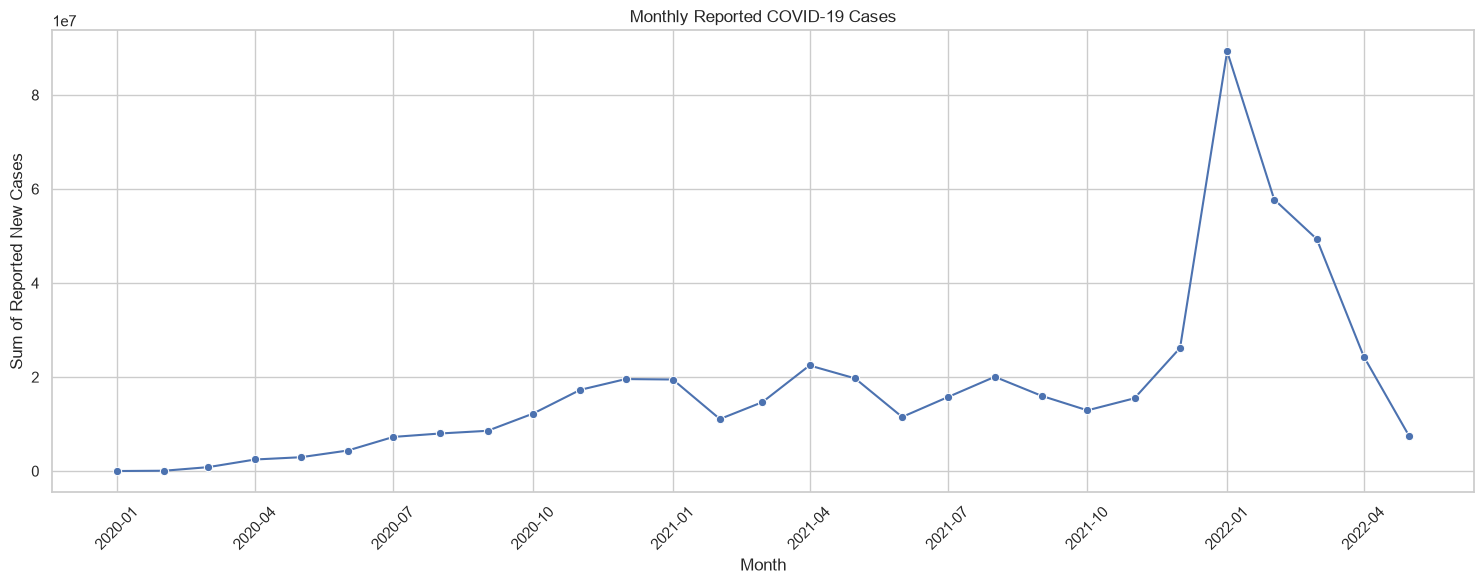

In [18]:
monthly_trend = (
    daily_trend.set_index("date")
    [["daily_cases", "daily_deaths"]]
    .resample("MS")
    .sum(min_count=1)
    .reset_index()
)

display(monthly_trend.head(12))

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_trend,
    x="date",
    y="daily_cases",
    marker="o"
)

plt.title("Monthly Reported COVID-19 Cases")
plt.xlabel("Month")
plt.ylabel("Sum of Reported New Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,country,active_cases
0,USA,17935434.0
1,France,6852832.0
2,Germany,4575633.0
3,UK,4459061.0
4,Spain,3846305.0
5,India,3741179.0
6,Brazil,3219406.0
7,Viet Nam,3169398.0
8,Italy,2759074.0
9,Russia,2683789.0


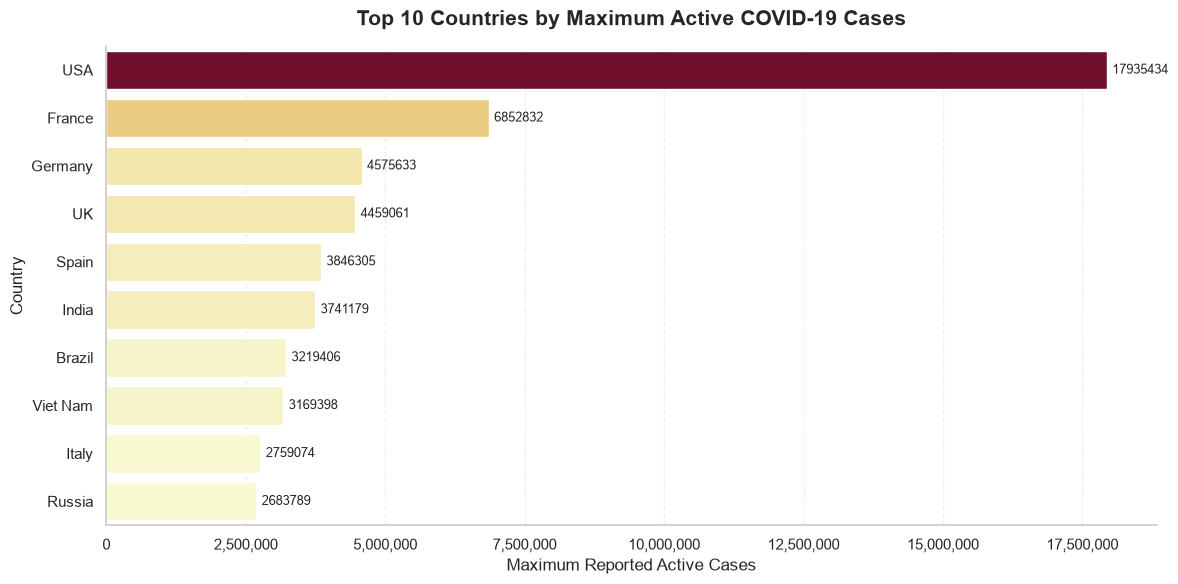

In [19]:
top_active = (
    df.groupby("country")["active_cases"]
      .max()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

display(top_active)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_active,
    x="active_cases",
    y="country",
    hue="active_cases",
    palette="YlOrRd",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4, fontsize=9)

plt.title("Top 10 Countries by Maximum Active COVID-19 Cases",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Maximum Reported Active Cases")
plt.ylabel("Country")
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
)
plt.grid(axis="x", linestyle="--", alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

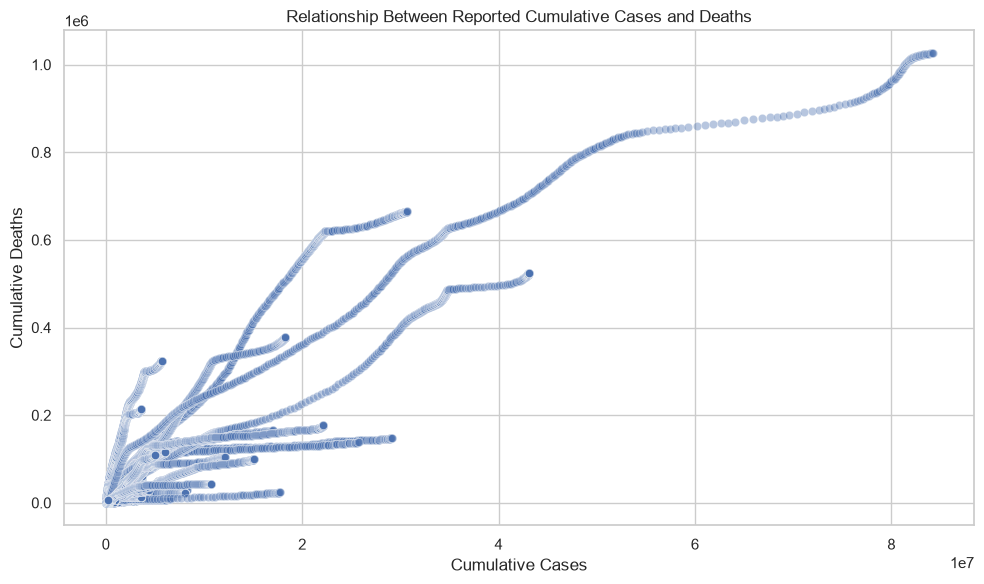

In [20]:
relationship_data = df[
    ["cumulative_total_cases", "cumulative_total_deaths"]
].dropna()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=relationship_data,
    x="cumulative_total_cases",
    y="cumulative_total_deaths",
    alpha=0.4
)

plt.title("Relationship Between Reported Cumulative Cases and Deaths")
plt.xlabel("Cumulative Cases")
plt.ylabel("Cumulative Deaths")
plt.tight_layout()
plt.show()

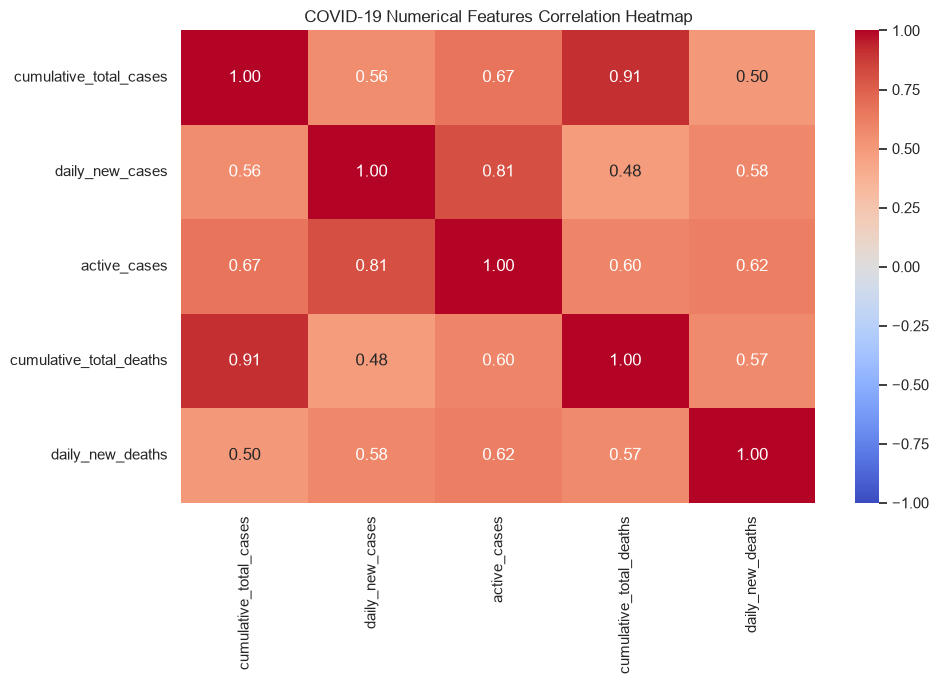

In [21]:
numeric_data = df[
    [
        "cumulative_total_cases",
        "daily_new_cases",
        "active_cases",
        "cumulative_total_deaths",
        "daily_new_deaths"
    ]
]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("COVID-19 Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()

In [22]:
import sqlite3
import pandas as pd
import os

DB_NAME = "covid19_analysis.db"

conn = sqlite3.connect(DB_NAME)

df.to_sql(
    "covid_records",
    conn,
    if_exists="replace",
    index=False
)

print("SQL database created successfully!")
print("Database:", DB_NAME)

SQL database created successfully!
Database: covid19_analysis.db


In [23]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

display(pd.read_sql_query(query, conn))

,name
0,covid_records


In [24]:
query = """
SELECT *
FROM covid_records
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))

,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
0,2020-02-15 00:00:00,Afghanistan,0,NaN,0.0,0.0,NaN
1,2020-02-25 00:00:00,Afghanistan,1,0.0,1.0,0.0,0.0
2,2020-03-22 00:00:00,Afghanistan,40,16.0,38.0,1.0,1.0
3,2020-03-23 00:00:00,Afghanistan,40,0.0,38.0,1.0,0.0
4,2020-03-25 00:00:00,Afghanistan,84,10.0,80.0,2.0,1.0
5,2020-03-26 00:00:00,Afghanistan,94,10.0,88.0,4.0,2.0
6,2020-03-27 00:00:00,Afghanistan,110,16.0,104.0,4.0,0.0
7,2020-04-02 00:00:00,Afghanistan,273,36.0,257.0,6.0,2.0
8,2020-04-03 00:00:00,Afghanistan,281,8.0,265.0,6.0,0.0
9,2020-04-04 00:00:00,Afghanistan,309,28.0,292.0,7.0,1.0


In [25]:
query = """
SELECT
    country,
    MAX(cumulative_total_cases) AS max_reported_cases
FROM covid_records
GROUP BY country
ORDER BY max_reported_cases DESC
LIMIT 10;
"""

top_cases_sql = pd.read_sql_query(query, conn)
display(top_cases_sql)

,country,max_reported_cases
0,USA,84209473
1,India,43121599
2,Brazil,30682094
3,France,29160802
4,Germany,25774509
5,UK,22159805
6,Russia,18255337
7,South Korea,17756627
8,Italy,17030711
9,Turkey,15053168


In [26]:
query = """
SELECT
    country,
    MAX(cumulative_total_deaths) AS max_reported_deaths
FROM covid_records
GROUP BY country
ORDER BY max_reported_deaths DESC
LIMIT 10;
"""

top_deaths_sql = pd.read_sql_query(query, conn)
display(top_deaths_sql)

,country,max_reported_deaths
0,USA,1026646.0
1,Brazil,664920.0
2,India,524214.0
3,Russia,377571.0
4,Mexico,324465.0
5,Peru,213023.0
6,UK,176708.0
7,Italy,165182.0
8,Indonesia,156453.0
9,France,147257.0


In [27]:
query = """
SELECT
    strftime('%Y', date) AS year,
    SUM(daily_new_cases) AS reported_new_cases,
    SUM(daily_new_deaths) AS reported_new_deaths,
    COUNT(*) AS records_available
FROM covid_records
GROUP BY strftime('%Y', date)
ORDER BY year;
"""

yearly_analysis = pd.read_sql_query(query, conn)
display(yearly_analysis)

,year,reported_new_cases,reported_new_deaths,records_available
0,2020,83589609.0,1952665.0,28858
1,2021,205235848.0,3525090.0,47850
2,2022,228063356.0,807238.0,15667


In [28]:
query = """
SELECT
    strftime('%Y-%m', date) AS month,
    SUM(daily_new_cases) AS reported_new_cases,
    SUM(daily_new_deaths) AS reported_new_deaths
FROM covid_records
GROUP BY strftime('%Y-%m', date)
ORDER BY month;
"""

monthly_sql = pd.read_sql_query(query, conn)
display(monthly_sql.head(20))

,month,reported_new_cases,reported_new_deaths
0,2020-01,11220.0,242.0
1,2020-02,70620.0,2691.0
2,2020-03,832619.0,42878.0
3,2020-04,2462991.0,201801.0
4,2020-05,2943093.0,168267.0
5,2020-06,4372334.0,157900.0
6,2020-07,7262997.0,185311.0
7,2020-08,7997681.0,190267.0
8,2020-09,8565101.0,162389.0
9,2020-10,12229970.0,183420.0


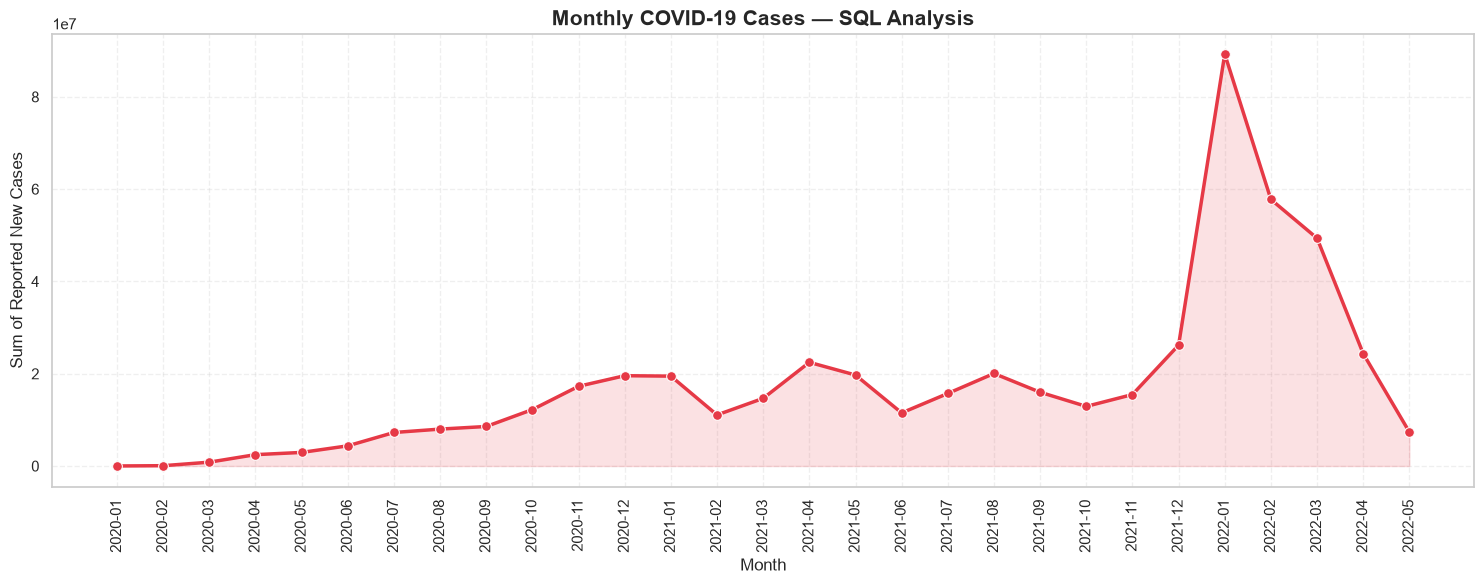

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=monthly_sql,
    x="month",
    y="reported_new_cases",
    marker="o",
    color="#E63946",
    linewidth=2.5,
    markersize=7
)

plt.fill_between(
    range(len(monthly_sql)),
    monthly_sql["reported_new_cases"],
    color="#E63946",
    alpha=0.15
)

plt.title("Monthly COVID-19 Cases — SQL Analysis",
          fontsize=15, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Sum of Reported New Cases")
plt.xticks(range(len(monthly_sql)), monthly_sql["month"], rotation=90)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
selected_country = "India"

query = """
SELECT
    date,
    country,
    cumulative_total_cases,
    daily_new_cases,
    active_cases,
    cumulative_total_deaths,
    daily_new_deaths
FROM covid_records
WHERE country = ?
ORDER BY date;
"""

country_analysis = pd.read_sql_query(
    query,
    conn,
    params=(selected_country,)
)

display(country_analysis.head(20))

,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
0,2020-03-17 00:00:00,India,143,14.0,126.0,3.0,1.0
1,2020-03-18 00:00:00,India,169,26.0,152.0,3.0,0.0
2,2020-03-20 00:00:00,India,249,55.0,221.0,5.0,1.0
3,2020-03-21 00:00:00,India,332,83.0,304.0,5.0,0.0
4,2020-03-23 00:00:00,India,499,103.0,454.0,11.0,3.0
5,2020-03-25 00:00:00,India,657,121.0,601.0,13.0,2.0
6,2020-03-26 00:00:00,India,727,70.0,661.0,21.0,8.0
7,2020-03-27 00:00:00,India,887,160.0,793.0,21.0,0.0
8,2020-03-28 00:00:00,India,987,100.0,878.0,25.0,4.0
9,2020-03-29 00:00:00,India,1024,37.0,901.0,28.0,3.0


In [31]:
query = """
SELECT
    date,
    country,
    daily_new_cases
FROM covid_records
WHERE daily_new_cases IS NOT NULL
ORDER BY daily_new_cases DESC
LIMIT 20;
"""

highest_daily_cases = pd.read_sql_query(query, conn)
display(highest_daily_cases)

,date,country,daily_new_cases
0,2022-01-13 00:00:00,USA,909610.0
1,2022-01-07 00:00:00,USA,903409.0
2,2022-01-12 00:00:00,USA,891103.0
3,2022-01-14 00:00:00,USA,890152.0
4,2022-01-21 00:00:00,USA,831049.0
5,2022-01-06 00:00:00,USA,828175.0
6,2022-01-08 00:00:00,USA,820458.0
7,2022-01-15 00:00:00,USA,784143.0
8,2022-01-20 00:00:00,USA,768758.0
9,2022-01-11 00:00:00,USA,764968.0


In [32]:
query = """
SELECT
    COUNT(*) AS total_records,
    SUM(CASE WHEN active_cases IS NULL THEN 1 ELSE 0 END)
        AS missing_active_cases,
    SUM(CASE WHEN daily_new_cases IS NULL THEN 1 ELSE 0 END)
        AS missing_daily_cases,
    SUM(CASE WHEN daily_new_deaths IS NULL THEN 1 ELSE 0 END)
        AS missing_daily_deaths
FROM covid_records;
"""

display(pd.read_sql_query(query, conn))

,total_records,missing_active_cases,missing_daily_cases,missing_daily_deaths
0,92375,8789,5,47


In [33]:
top_cases_sql.to_csv("sql_top_countries_cases.csv", index=False)
top_deaths_sql.to_csv("sql_top_countries_deaths.csv", index=False)
yearly_analysis.to_csv("sql_yearly_analysis.csv", index=False)
monthly_sql.to_csv("sql_monthly_analysis.csv", index=False)
highest_daily_cases.to_csv("sql_highest_daily_cases.csv", index=False)

print("SQL analysis files exported successfully!")

SQL analysis files exported successfully!


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine Learning libraries loaded!")

Machine Learning libraries loaded!


In [35]:
countries = sorted(df["country"].dropna().unique())

selected_country = (
    "India" if "India" in countries else countries[0]
)

country_df = df[
    df["country"] == selected_country
].copy()

country_df = (
    country_df.sort_values("date")
    .dropna(subset=["date", "cumulative_total_cases"])
    .drop_duplicates(subset=["date"], keep="last")
)

print("Selected Country:", selected_country)
print("Total observations:", len(country_df))
print("Start Date:", country_df["date"].min())
print("End Date:", country_df["date"].max())

display(country_df.head())

Selected Country: India
Total observations: 786
Start Date: 2020-03-17 00:00:00
End Date: 2022-05-14 00:00:00


,date,country,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
36572,2020-03-17,India,143,14.0,126.0,3.0,1.0
36573,2020-03-18,India,169,26.0,152.0,3.0,0.0
36574,2020-03-20,India,249,55.0,221.0,5.0,1.0
36575,2020-03-21,India,332,83.0,304.0,5.0,0.0
36576,2020-03-23,India,499,103.0,454.0,11.0,3.0


In [36]:
country_series = (
    country_df.set_index("date")["cumulative_total_cases"]
    .sort_index()
)

daily_index = pd.date_range(
    start=country_series.index.min(),
    end=country_series.index.max(),
    freq="D"
)

daily_series = country_series.reindex(daily_index)

daily_series = daily_series.interpolate(
    method="time",
    limit_area="inside"
)

daily_series = daily_series.ffill().clip(lower=0)

# Cumulative cases se estimated daily cases
daily_cases = daily_series.diff().fillna(0).clip(lower=0)

ml_df = pd.DataFrame({
    "date": daily_index,
    "cumulative_cases_estimated": daily_series.values,
    "daily_cases_estimated": daily_cases.values
})

print("Prepared daily timeline:", ml_df.shape)
display(ml_df.head(10))

Prepared daily timeline: (789, 3)


,date,cumulative_cases_estimated,daily_cases_estimated
0,2020-03-17,143.0,0.0
1,2020-03-18,169.0,26.0
2,2020-03-19,209.0,40.0
3,2020-03-20,249.0,40.0
4,2020-03-21,332.0,83.0
5,2020-03-22,415.5,83.5
6,2020-03-23,499.0,83.5
7,2020-03-24,578.0,79.0
8,2020-03-25,657.0,79.0
9,2020-03-26,727.0,70.0


In [37]:
ml_df["lag_1"] = ml_df["daily_cases_estimated"].shift(1)
ml_df["lag_2"] = ml_df["daily_cases_estimated"].shift(2)
ml_df["lag_3"] = ml_df["daily_cases_estimated"].shift(3)
ml_df["lag_7"] = ml_df["daily_cases_estimated"].shift(7)
ml_df["lag_14"] = ml_df["daily_cases_estimated"].shift(14)

ml_df["rolling_mean_7"] = (
    ml_df["daily_cases_estimated"]
    .shift(1)
    .rolling(7)
    .mean()
)

ml_df["rolling_mean_14"] = (
    ml_df["daily_cases_estimated"]
    .shift(1)
    .rolling(14)
    .mean()
)

ml_df["day_of_week"] = ml_df["date"].dt.dayofweek
ml_df["day_of_year"] = ml_df["date"].dt.dayofyear

ml_df = ml_df.dropna().reset_index(drop=True)

print("Machine Learning dataset shape:", ml_df.shape)
display(ml_df.head())

Machine Learning dataset shape: (775, 12)


,date,cumulative_cases_estimated,daily_cases_estimated,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7,rolling_mean_14,day_of_week,day_of_year
0,2020-03-31,1397.0,146.0,227.0,37.0,100.0,79.0,0.0,107.428571,79.142857,1,91
1,2020-04-01,1998.0,601.0,146.0,227.0,37.0,79.0,26.0,117.000000,89.571429,2,92
2,2020-04-02,2543.0,545.0,601.0,146.0,227.0,70.0,40.0,191.571429,130.642857,3,93
3,2020-04-03,3059.0,516.0,545.0,601.0,146.0,160.0,40.0,259.428571,166.714286,4,94
4,2020-04-04,3588.0,529.0,516.0,545.0,601.0,100.0,83.0,310.285714,200.714286,5,95


In [38]:
features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "day_of_week",
    "day_of_year"
]

X = ml_df[features]
y = ml_df["daily_cases_estimated"]

split_index = int(len(ml_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training period:",
      ml_df["date"].iloc[0], "to",
      ml_df["date"].iloc[split_index - 1])
print("Testing period:",
      ml_df["date"].iloc[split_index], "to",
      ml_df["date"].iloc[-1])

Training records: 620
Testing records: 155
Training period: 2020-03-31 00:00:00 to 2021-12-10 00:00:00
Testing period: 2021-12-11 00:00:00 to 2022-05-14 00:00:00


In [39]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

baseline_predictions = np.maximum(
    0,
    baseline_model.predict(X_test)
)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [40]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = np.maximum(
    0,
    rf_model.predict(X_test)
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [41]:
def evaluate_model(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

comparison = pd.DataFrame([
    evaluate_model(
        y_test, baseline_predictions, "Mean Baseline"
    ),
    evaluate_model(
        y_test, rf_predictions, "Random Forest"
    )
])

display(comparison)

,Model,MAE,RMSE,R2
0,Mean Baseline,71819.235120,93439.893965,-0.000256
1,Random Forest,7632.119376,13381.580395,0.979485


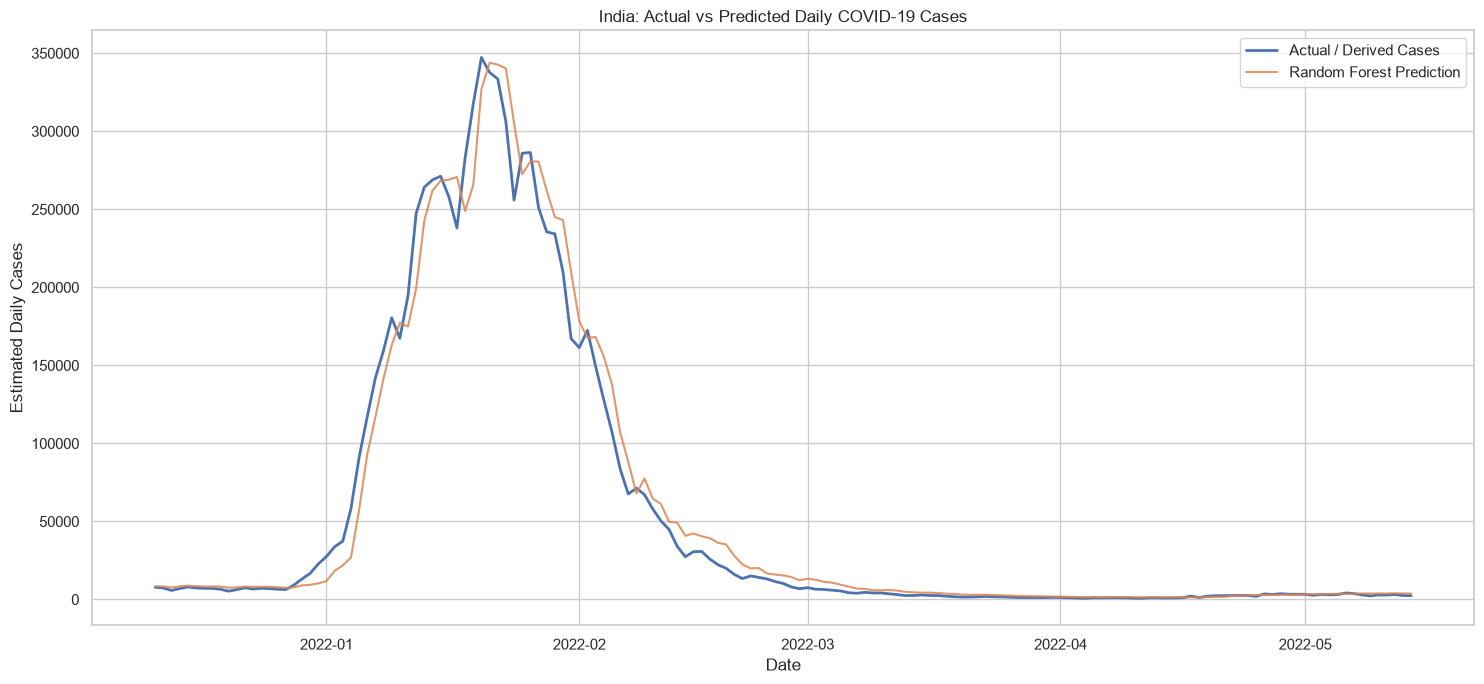

In [42]:
prediction_results = pd.DataFrame({
    "Date": ml_df["date"].iloc[split_index:].values,
    "Actual_Estimated_Cases": y_test.values,
    "Baseline_Prediction": baseline_predictions,
    "Random_Forest_Prediction": rf_predictions
})

plt.figure(figsize=(15, 7))

plt.plot(
    prediction_results["Date"],
    prediction_results["Actual_Estimated_Cases"],
    label="Actual / Derived Cases",
    linewidth=2
)

plt.plot(
    prediction_results["Date"],
    prediction_results["Random_Forest_Prediction"],
    label="Random Forest Prediction",
    alpha=0.85
)

plt.title(
    f"{selected_country}: Actual vs Predicted Daily COVID-19 Cases"
)
plt.xlabel("Date")
plt.ylabel("Estimated Daily Cases")
plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
0,lag_1,0.802236
1,lag_2,0.146318
2,lag_3,0.025506
5,rolling_mean_7,0.021298
3,lag_7,0.001962
8,day_of_year,0.001332
7,day_of_week,0.000709
4,lag_14,0.000358
6,rolling_mean_14,0.000281


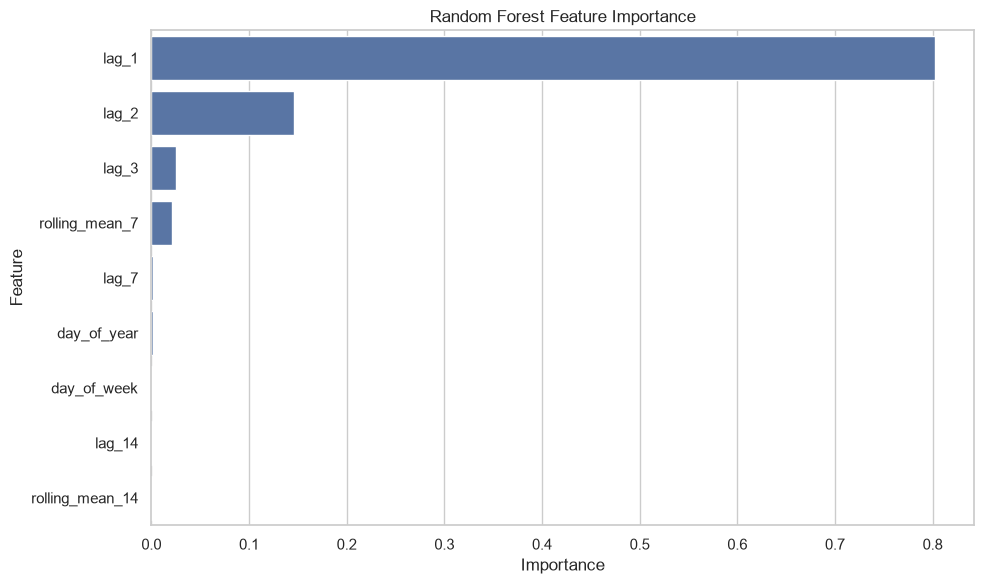

In [43]:
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [44]:
comparison.to_csv(
    "ml_model_comparison.csv",
    index=False
)

prediction_results.to_csv(
    "ml_test_predictions.csv",
    index=False
)

importance_df.to_csv(
    "ml_feature_importance.csv",
    index=False
)

print("Machine Learning results saved successfully!")

Machine Learning results saved successfully!


NameError: name 'future_forecast' is not defined

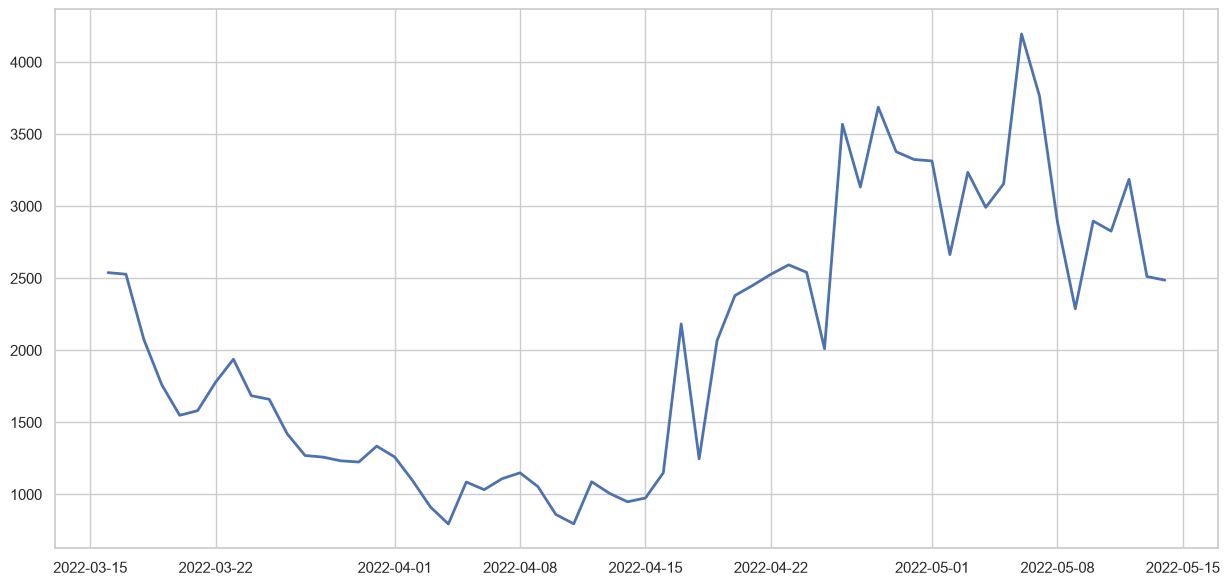

In [45]:
recent_history = ml_df.tail(60)

plt.figure(figsize=(15, 7))

plt.plot(
    recent_history["date"],
    recent_history["daily_cases_estimated"],
    label="Historical / Derived Cases",
    linewidth=2
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Daily_Cases"],
    marker="o",
    linestyle="--",
    label="14-Day Forecast"
)

plt.axvline(
    recent_history["date"].max(),
    linestyle=":",
    label="Forecast Start"
)

plt.title(
    f"{selected_country}: COVID-19 Daily Cases Forecast"
)
plt.xlabel("Date")
plt.ylabel("Estimated Daily Cases")
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
future_forecast.to_csv(
    "COVID19_14_Day_Forecast.csv",
    index=False
)

comparison.to_csv(
    "COVID19_Model_Comparison.csv",
    index=False
)

prediction_results.to_csv(
    "COVID19_Test_Predictions.csv",
    index=False
)

importance_df.to_csv(
    "COVID19_Feature_Importance.csv",
    index=False
)

print("All Machine Learning outputs saved successfully!")

NameError: name 'future_forecast' is not defined

In [46]:
print("=" * 55)
print("COVID-19 PROJECT: FINAL SUMMARY")
print("=" * 55)

print("Selected Country:", selected_country)
print("Total cleaned records:", len(df))
print("Countries covered:", df["country"].nunique())
print(
    "Dataset date range:",
    df["date"].min().date(),
    "to",
    df["date"].max().date()
)

print("\nMODEL COMPARISON")
display(comparison.round(3))

best_model = comparison.loc[
    comparison["MAE"].idxmin(), "Model"
]

print("Lowest MAE model:", best_model)

print("\nTOP 5 COUNTRIES BY REPORTED CUMULATIVE CASES")
display(top_cases.head())

print("\nTOP 5 COUNTRIES BY REPORTED CUMULATIVE DEATHS")
display(top_deaths.head())

print("\nFORECAST PREVIEW")
display(future_forecast.head())

print("\nProject analysis completed.")

COVID-19 PROJECT: FINAL SUMMARY
Selected Country: India
Total cleaned records: 92375
Countries covered: 215
Dataset date range: 2020-01-22 to 2022-05-14

MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Mean Baseline,71819.235,93439.894,-0.000
1,Random Forest,7632.119,13381.580,0.979


Lowest MAE model: Random Forest

TOP 5 COUNTRIES BY REPORTED CUMULATIVE CASES


,country,cumulative_total_cases
0,USA,84209473
1,India,43121599
2,Brazil,30682094
3,France,29160802
4,Germany,25774509



TOP 5 COUNTRIES BY REPORTED CUMULATIVE DEATHS


,country,cumulative_total_deaths
0,USA,1026646.0
1,Brazil,664920.0
2,India,524214.0
3,Russia,377571.0
4,Mexico,324465.0



FORECAST PREVIEW


NameError: name 'future_forecast' is not defined